In [1]:
import sys
import os
import numpy as np
sys.path.append(os.path.abspath('../../'))
from BWM.models.isometric_autoencoder import SklearnIsometricAutoencoder
from RNN.models.rnn import Net, compute_zscored_derivatives

In [2]:
# Modulate the curvature index of each neuron.
import torch
from torch import optim
import torch.nn as nn
import seaborn as sns
from matplotlib import gridspec
from RNN.Experiment_10.ParametricWMTask import generate_trials
import matplotlib.pyplot as plt
import matplotlib
import umap
from sklearn.decomposition import PCA
plt.rcParams["axes.grid"] = False
matplotlib.rcParams['axes.linewidth'] = .5
device= 'cpu'

In [3]:
pwd

'/Users/cl1704/PycharmProjects/embedding_dimension/RNN/Notebooks'

In [4]:
# %%
# %%

In [5]:
import torch

# %%
# %%

# Example Usage:
# z_y, dz = compute_zscored_derivatives(y_tensor, dt=0.01)

def plot_curvature_vs_arclength(rnn, step_size, total_time):
    """
    Plots curvature vs arc length and time series for four neurons with evenly spaced g values.
    First row: Curvature vs Arc Length.
    Second row: Time series y_i(t).
    Trials colored by angle of the input at the first time point.
    Highlight trial: trial with largest peak curvature.
    """
    n_steps = int(total_time / step_size)
    rnn.eval()
    original_alpha = rnn.alpha.item()
    rnn.alpha = torch.tensor(step_size)
    
    with torch.no_grad():
        # 1. Generate trials and get states
        u, _, _, _ = generate_trials(n_trials=1, n_conditions=100, n_t=n_steps)
        u = u.to(next(rnn.parameters()).device)
        states = rnn(u) # (trials, n_t, neurons)
        num_trials = states.shape[0]
        num_neurons = states.shape[2]
        
        # Calculate angles from the first time point of u
        angles = torch.atan2(u[:, 0, 1], u[:, 0, 0]).cpu().numpy()
        norm_angles = (angles + np.pi) / (2 * np.pi)
        
        # 2. Get h (pre-activation) and y
        inputs = rnn.input_layer(u)
        h = rnn.recurrent_layer(states) + inputs # (trials, n_t, neurons)
        y = states # (trials, n_t, neurons)
        
        # Calculate arc length s
        diffs = torch.diff(y, dim=1)
        step_lengths = torch.norm(diffs, p=2, dim=2)
        arc_length = torch.zeros(y.shape[0], y.shape[1], device=y.device)
        arc_length[:, 1:] = torch.cumsum(step_lengths, dim=1)

        # 3. Calculate dot_h and dot_y
        dt = step_size
        res = compute_zscored_derivatives(y, rnn, u, dt=dt, total_time=total_time)
        if len(res) == 3:
            _, dot_y, dot_h = res
        else:
            _, dot_y = res
            dot_h = torch.matmul(dot_y, rnn.recurrent_layer.weight.t())

        # Calculate z-scored dot_y for selection and plotting
        y_mean = y.mean(dim=(0, 1), keepdim=True)
        y_std = y.std(dim=(0, 1), keepdim=True)
        dot_y_z = dot_y / (y_std + 1e-8)
        
        # 4. Calculate f''(h)
        beta = rnn.beta
        sigmoid = torch.sigmoid(beta * h)
        f_pp = beta**2 * sigmoid* (1 - sigmoid)
    
        # Curvature quantity: (dot_h_i)^2 * f''(h_i)
        curvature_all = (dot_h**2) * f_pp # (trials, n_t, neurons)
        
        # Calculate g for each neuron as in the training loop
        # g = mean of absolute value of z-scored temporal derivatives
        g_vals = torch.mean(torch.abs(dot_y_z), dim=(0, 1)).cpu().numpy()
        sorted_indices = np.argsort(g_vals)
        
        # Pick 3 neurons: min, median, and max g
        median_idx = num_neurons // 2
        selected_idx_into_sorted = [0, median_idx, num_neurons - 1]
        selected_neurons = sorted_indices[selected_idx_into_sorted]
        
        # 5. Plot
        fig, axes = plt.subplots(4, 3, figsize=(15, 20))
        cmap = plt.get_cmap('coolwarm')
        colors_list = [cmap(i / (num_trials - 1)) for i in range(num_trials)]
        
        # To synchronize y-axis for curvature, y, dot_y, and dot_h plots
        curv_min = curvature_all[:, :, selected_neurons].min().item()
        curv_max = curvature_all[:, :, selected_neurons].max().item()
        y_min = y[:, :, selected_neurons].min().item()
        y_max = y[:, :, selected_neurons].max().item()
        doty_z_min = dot_y_z[:, :, selected_neurons].min().item()
        doty_z_max = dot_y_z[:, :, selected_neurons].max().item()
        doth_min = dot_h[:, :, selected_neurons].min().item()
        doth_max = dot_h[:, :, selected_neurons].max().item()
        h_min = h[:, :, selected_neurons].min().item()
        h_max = h[:, :, selected_neurons].max().item()
        
        for i, neuron_idx in enumerate(selected_neurons):
            # Identify highlight trial: trial with largest max curvature for this neuron
            peak_curvatures = torch.max(curvature_all[:, :, neuron_idx], dim=1)[0].cpu().numpy()
            highlight_idx = np.argmax(peak_curvatures)
            
            ax_curv = axes[0, i]
            ax_time = axes[1, i]
            ax_doty_arc = axes[2, i]
            ax_doth = axes[3, i]
            
            for trial_idx in range(num_trials):
                color = colors_list[trial_idx]
                
                # Curvature plot
                s_plot = arc_length[trial_idx, :].cpu().numpy()
                curv_plot = curvature_all[trial_idx, :, neuron_idx].cpu().numpy()
                ax_curv.plot(s_plot, curv_plot, color=color, alpha=0.3, linewidth=1.0, zorder=1)
                
                # Time series plot
                y_tn = y[trial_idx, :, neuron_idx].cpu().numpy()
                t_plot = np.arange(len(y_tn))
                ax_time.plot(t_plot, y_tn, color=color, alpha=0.3, linewidth=1.0, zorder=1)
                
                # dot_y vs Arc Length
                dh = dot_h[trial_idx, :, neuron_idx].cpu().numpy()
                dy_z = dot_y_z[trial_idx, :, neuron_idx].cpu().numpy()
                ax_doty_arc.plot(s_plot, np.abs(dy_z), color=color, alpha=0.3, linewidth=1.0, zorder=1)

                # dot_h vs arc length plot
                ax_doth.plot(s_plot, dh, color=color, alpha=0.3, linewidth=1.0, zorder=1)
                
                # Crossings
                h_tn_torch = h[trial_idx, :, neuron_idx]
                signs = torch.sign(h_tn_torch)
                signs[signs == 0] = 1
                crossings = torch.where(signs[:-1] != signs[1:])[0]
                for c_idx in crossings:
                    color_c = colors_list[trial_idx]
                    ax_curv.axvline(x=arc_length[trial_idx, c_idx].cpu().item(), color=color_c, linestyle='--', alpha=0.05, zorder=0)
                    ax_time.axvline(x=c_idx.cpu().item(), color=color_c, linestyle='--', alpha=0.05, zorder=0)
                    ax_doty_arc.axvline(x=arc_length[trial_idx, c_idx].cpu().item(), color=color_c, linestyle='--', alpha=0.05, zorder=0)
                    ax_doth.axvline(x=arc_length[trial_idx, c_idx].cpu().item(), color=color_c, linestyle='--', alpha=0.05, zorder=0)

            ax_curv.set_title(f'Neuron {neuron_idx}\ng={g_vals[neuron_idx]:.4f}', fontsize=12)
            ax_curv.set_xlabel('Arc Length', fontsize=10)
            if i == 0: ax_curv.set_ylabel('Curvature', fontsize=10)
            ax_curv.set_ylim(curv_min, curv_max)
            
            ax_time.set_xlabel('Time Step', fontsize=10)
            if i == 0: ax_time.set_ylabel(f'y(t)', fontsize=10)
            ax_time.set_ylim(y_min, y_max)
            
            ax_doty_arc.set_xlabel('Arc Length', fontsize=10)
            if i == 0: ax_doty_arc.set_ylabel(r'$|\dot{z}_i|$', fontsize=10)
            ax_doty_arc.set_ylim(0, doty_z_max if doty_z_max > 0 else 1e-8)
            
            ax_doth.set_xlabel('Arc Length', fontsize=10)
            if i == 0: ax_doth.set_ylabel(r'$\dot{h}_i$', fontsize=10)
            ax_doth.set_ylim(doth_min, doth_max)
            
            if i == 2: ax_curv.legend(loc='upper right', fontsize=8)

            for ax in [ax_curv, ax_time, ax_doty_arc, ax_doth]:
                ax.tick_params(labelsize=8)
                sns.despine(ax=ax)

        plt.tight_layout()
        plt.suptitle('Curvature, Time Series, dot_y, and dot_h for Selected Neurons', fontsize=16)
        plt.subplots_adjust(top=0.92)
        plt.show()
        
    # Restore original alpha
    rnn.alpha = torch.tensor(original_alpha)







In [6]:
import numpy as np

def generate_balanced_weights(n, p_e=0.8, g=4.0):
    """
    Generates a balanced recurrent connectivity matrix of size N.

    Parameters:
    -----------
    n : int
        Total number of neurons in the network (must be an even integer).
    p_e : float
        Fraction of neurons that are Excitatory (default 80%).
    g : float
        Inhibitory relative strength multiplier (typically > 1 to ensure stability).

    Returns:
    --------
    W : numpy.ndarray
        An (N, N) matrix where columns represent presynaptic neurons and
        rows represent postsynaptic neurons.
    """
    if n % 2 != 0:
        raise ValueError("Network size 'n' should be an even integer for clean splitting.")

    # 1. Determine population sizes
    n_e = int(n * p_e)
    n_i = n - n_e

    # 2. Define the base scaling factor 1/sqrt(N)
    # This prevents the net variance of the inputs from exploding as N grows.
    scale = 1.0 / np.sqrt(n)

    # Mean strengths for the 4 connection blocks
    # Excitatory columns will have positive means, Inhibitory columns negative means
    w_ee_mean = 1.0 * scale
    w_ie_mean = 1.0 * scale
    w_ei_mean = -g * scale
    w_ii_mean = -g * scale

    # 3. Initialize empty matrix
    W = np.zeros((n, n))

    # 4. Fill Excitatory Presynaptic Columns (0 to n_e)
    # Standard deviation scales with 1/sqrt(n) to maintain variance balance
    W[:, :n_e] = np.random.normal(loc=w_ee_mean, scale=scale, size=(n, n_e))
    # Enforce Dale's Law: Excitatory neurons can only project positive values
    W[:, :n_e] = np.maximum(0, W[:, :n_e])

    # 5. Fill Inhibitory Presynaptic Columns (n_e to n)
    W[:, n_e:] = np.random.normal(loc=w_ei_mean, scale=scale, size=(n, n_i))
    # Enforce Dale's Law: Inhibitory neurons can only project negative values
    W[:, n_e:] = np.minimum(0, W[:, n_e:])

    # 6. Apply individual row-wise correction (Self-Coupling Balance)
    # Ensure that for every single neuron, the structural E and I block means
    # roughly cancel out so h_i doesn't explode before dynamics even start.
    return W

# Example usage:
# W = generate_balanced_weights(n=1000, p_e=0.8, g=4.5)


In [66]:
class DifferentiableTwoNN(nn.Module):
    def __init__(self, temperature: float = 0.01):
        """
        Differentiable Two-Nearest-Neighbors (TwoNN) Intrinsic Dimension Estimator.
        Uses only R1 and R2 to eliminate high-dimensional distance concentration.
        """
        super().__init__()
        self.temperature = temperature
        self.eps = 1e-7

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # Input shape: (n_neurons, t)
        x = x.float()
        n_neurons, t = x.shape

        # 1. Compute pairwise distance matrix per neuron over time
        x_expanded = x.unsqueeze(-1)
        dist_matrix = torch.cdist(x_expanded, x_expanded, p=2) # (n_neurons, t, t)

        # 2. Mask the self-distance diagonal (set to a very high value)
        diagonal_mask = torch.eye(t, device=x.device).unsqueeze(0) * 1e8
        masked_dists_1 = dist_matrix + diagonal_mask

        # 3. Softly extract R1 (the absolute closest neighbor distance)
        # Using softmin (softmax of negative values) to isolate the minimum
        r1_weights = torch.softmax(-masked_dists_1 / self.temperature, dim=-1)
        r1 = torch.sum(r1_weights * dist_matrix, dim=-1) # (n_neurons, t)

        # 4. Softly mask out R1 to isolate R2
        # We add a massive penalty to the position that was just selected as R1
        masked_dists_2 = masked_dists_1 + (r1_weights * 1e8)

        # 5. Softly extract R2 (the second closest neighbor distance)
        r2_weights = torch.softmax(-masked_dists_2 / self.temperature, dim=-1)
        r2 = torch.sum(r2_weights * dist_matrix, dim=-1) # (n_neurons, t)

        # 6. Apply the exact TwoNN Maximum Likelihood Formula:
        # ID = 1 / mean( log(R2 / R1) )
        # To avoid uniform collapse, we compute log(R2/R1) per timepoint first
        ratio = torch.log((r2 + self.eps) / (r1 + self.eps))

        # Clip to prevent log(1) = 0 division explosions
        ratio = torch.clamp(ratio, min=self.eps)

        # Local intrinsic dimension profile per timepoint
        id_per_timepoint = 1.0 / ratio # For TwoNN, numerator is strictly 1.0

        # 7. Mean across time to find the localized ID signature per neuron
        id_estimates = torch.mean(id_per_timepoint, dim=-1) # (n_neurons,)

        return id_estimates

import torch

def project_to_top_k_pcs(x: torch.Tensor, k: int = 25, jitter_eps: float = 1e-6) -> torch.Tensor:
    """
    Robustly projects an input tensor (n_neurons, t) onto its top k PCs,
    handling convergence errors natively.
    """
    orig_device = x.device
    orig_dtype = x.dtype

    # 1. Clean data: Remove any NaN/Infs and add a tiny jitter to break identical row symmetries
    x = torch.nan_to_num(x, nan=0.0, posinf=0.0, neginf=0.0)
    jitter = torch.randn_like(x) * jitter_eps
    x_buffered = x + jitter

    # 2. Mean center over the time dimension
    mean = torch.mean(x_buffered, dim=-1, keepdim=True)
    x_centered = x_buffered - mean

    # 3. Cast to float64 (double precision) specifically for the SVD calculation
    # This prevents numerical underflow/overflow errors common in float16/float32
    x_centered_64 = x_centered.to(torch.float64)

    try:
        # Check if we are on MPS and fallback if necessary, as standard fast SVD might not be implemented
        if orig_device.type == 'mps':
            raise torch._C._LinAlgError("MPS fallback triggered")
        # Try standard fast SVD
        U, S, Vh = torch.linalg.svd(x_centered_64, full_matrices=False)
    except (torch._C._LinAlgError, RuntimeError):
        # FALLBACK: If GPU driver fails to converge, compute SVD on CPU (LAPACK backend)
        # This is incredibly stable and bypasses driver-level convergence errors or missing MPS ops
        x_cpu = x_centered_64.cpu()
        U_cpu, S_cpu, Vh_cpu = torch.linalg.svd(x_cpu, full_matrices=False)
        U = U_cpu.to(orig_device)

    # 4. Truncate to the top k components and project
    projection_matrix = U[:, :k]  # Shape: (n_neurons, k)
    x_projected = torch.matmul(projection_matrix.t(), x_centered_64.to(orig_device))  # Shape: (k, t)

    # 5. Return original precision/device shaped as (t, k)
    return x_projected.t().to(dtype=orig_dtype)

# --- Integrated Pipeline Call ---
# stride = 4
# downsampled_activity = neuron_activity[:, ::stride]
# clean_pcs = project_to_top_k_pcs_robust(downsampled_activity, k=25)
# intrinsic_dims = estimator(clean_pcs)


In [454]:

rnn = Net(n=2000, input_size=4,
          sigma_in=0.,
          sigma_rec = 0.,
          base_in=0,
          beta=
          10,
          alpha = .05)

#rnn.recurrent_layer.weight.data = torch.FloatTensor(generate_balanced_weights(n=2000, p_e=0.8, g=4.5))

In [455]:

estimator = DifferentiableTwoNN(temperature=0.01)


criterion = nn.MSELoss()
optimizer = optim.Adam(rnn.parameters(), lr=0.001,weight_decay = .001)
#scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, 'min', patience=5)

# 4. Training Loop
epochs = 200
from RNN.Tasks.NonlinearTask import generate_nonlinear_circle_trials
input_dim = 4
complexity = 5
n_t = 50
u, z, mask, conditions = generate_nonlinear_circle_trials(n_trials=1, n_t=n_t, n_conditions=100, input_dim=input_dim, complexity=complexity)
u, z, mask = u.to(device), z.to(device), mask.to(device)

#u, z, mask, conditions = generate_trials(n_trials=1,n_conditions =25,n_t = 50,stim_on=0,stim_off = 50)

for epoch in range(epochs):
    rnn.train()
    optimizer.zero_grad()

    # Forward pass
    y = rnn(u)
    z_scored_y, dot_z = compute_zscored_derivatives(y, rnn, u, dt=rnn.alpha, total_time=50*rnn.alpha, epsilon=1e-8)
    g = torch.mean(torch.abs(dot_z),dim = (0,1))
    reg_loss =  torch.std(torch.std(y, dim=[0, 1])) + torch.std(torch.mean(y, dim=[0, 1]))

    # Dimensionality
    eigs = torch.sort(torch.real(
            torch.linalg.eigvals(torch.cov(y.reshape(-1, y.shape[2]).t()))),
                          descending=True)[0]
    fve = eigs/torch.sum(eigs)


   # id = estimator(project_to_top_k_pcs(z_scored_y.reshape(-1,z_scored_y.shape[2]).t(), k= 20))
    loss = .1*reg_loss + .01*(torch.mean(g)-.5)**2 #+ .1*fve[0]

    #loss = criterion(g, .1*target_g)+lambda_reg*reg_loss
    #loss = (torch.mean(g)-1)**2
    loss.backward()
    optimizer.step()
    #rnn.recurrent_layer.bias.data = torch.nn.ReLU()(rnn.recurrent_layer.bias.data)

    # Print statements
    if epoch % 10 == 0:
        print(f"Epoch [{epoch}/{epochs}] | loss: {loss.item():.4f} | reg: {reg_loss.item():.4f} | g_mean: {torch.mean(g).item():.4f} | std_g: {torch.std(g).item():.4f}")

Epoch [0/200] | loss: 0.0340 | reg: 0.3154 | g_mean: 0.9938 | std_g: 0.1877
Epoch [10/200] | loss: 0.0072 | reg: 0.0699 | g_mean: 0.6517 | std_g: 0.0820
Epoch [20/200] | loss: 0.0023 | reg: 0.0204 | g_mean: 0.6680 | std_g: 0.0618
Epoch [30/200] | loss: 0.0032 | reg: 0.0259 | g_mean: 0.7479 | std_g: 0.0576
Epoch [40/200] | loss: 0.0035 | reg: 0.0277 | g_mean: 0.7774 | std_g: 0.0572
Epoch [50/200] | loss: 0.0027 | reg: 0.0210 | g_mean: 0.7537 | std_g: 0.0603


KeyboardInterrupt: 

In [456]:
def get_density(x, k=50):
    """
    Computes the average k-NN distance in the input space as a proxy for inverse density.
    """
    if isinstance(x, np.ndarray):
        x = torch.FloatTensor(x)

    batch_size = x.shape[0]
    k = min(k, batch_size - 1)

    # We might need to do this in batches if x is very large
    if batch_size > 2000:
        avg_dists = []
        for i in range(0, batch_size, 1000):
            batch_x = x[i:i+1000]
            # Compute distances from batch to all points
            dists = torch.cdist(batch_x, x)
            knn_dist, _ = torch.topk(dists, k + 1, largest=False)
            avg_dists.append(knn_dist[:, 1:].mean(dim=1))
        return torch.cat(avg_dists, dim=0)
    else:
        x_dist = torch.cdist(x, x)
        x_knn_dist, _ = torch.topk(x_dist, k + 1, largest=False)
        return x_knn_dist[:, 1:].mean(dim=1)


import torch

Text(-0.05, 1, 'c')

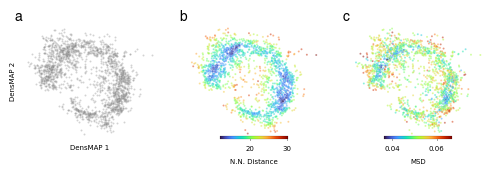

In [460]:
from sklearn.model_selection import KFold
from tqdm.auto import tqdm
import os
import sys
import matplotlib.gridspec as gridspec
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

y = rnn(u)
z = (y-torch.mean(y,dim=(0,1))) / torch.std(y,dim=(0,1))

g = torch.mean(torch.abs(torch.diff(z,dim=1)),dim = (0,1))

x  = y.detach()
x = (x-torch.mean(x,dim=(0,1)))/torch.std(x,dim=(0,1))
x = x.reshape(-1,x.shape[2]).detach().numpy().T
z_neurons = umap.UMAP(densmap=True,dens_lambda=1,n_neighbors=1000).fit_transform(x)
loc_density = get_density(x, k=50).numpy()




fig = plt.figure(figsize=(6, 1.5))
gs = gridspec.GridSpec(1, 3)
ax1 = plt.subplot(gs[0])
ax2 = plt.subplot(gs[1])
ax3 = plt.subplot(gs[2])








# Gray
sns.scatterplot(x=z_neurons[:, 0], y=z_neurons[:, 1], color='gray', s=2, alpha=.35,ax=ax1)

# NN Distance
sns.scatterplot(x=z_neurons[:, 0], y=z_neurons[:, 1], c=loc_density,cmap  = 'turbo', s=2, alpha=.5,ax=ax2)
cax = inset_axes(
        ax2, width="50%", height="2%",
        loc="lower center", borderpad=0
    )

norm = plt.Normalize(loc_density.min(), loc_density.max())
sm = plt.cm.ScalarMappable(cmap="turbo", norm=norm)
cb = fig.colorbar(sm, cax=cax, orientation="horizontal")
cb.outline.set_linewidth(0.1)
cax.set_xlabel("N.N. Distance", fontsize=5, labelpad=5)
cax.xaxis.set_tick_params(size=1, width=.5, color="black")
cax.xaxis.set_tick_params(labelsize=5)

# MSD

sns.scatterplot(x=z_neurons[:, 0], y=z_neurons[:, 1], c=g.detach(),cmap='turbo', s=2, alpha=.5,ax=ax3)
cax = inset_axes(
        ax3, width="50%", height="2%",
        loc="lower center", borderpad=0
    )
norm = plt.Normalize(g.min(), g.max())
sm = plt.cm.ScalarMappable(cmap="turbo", norm=norm)
cb = fig.colorbar(sm, cax=cax, orientation="horizontal")
cb.outline.set_linewidth(0.1)
cax.set_xlabel("MSD", fontsize=5, labelpad=5)
cax.xaxis.set_tick_params(size=1, width=.5, color="black")
cax.xaxis.set_tick_params(labelsize=5)





# 4. Global figure customizations
#fig.suptitle("Main Title for All 5 Subplots", fontsize=18, fontweight="bold", y=1.05)

# Automatically adjusts subplot parameters so that the labels don't overlap
for ax in [ax1,ax2,ax3]:
    for spine in ax.spines.values():
        spine.set_visible(False)

    # 2. Hide the tick marks and tick numbers
    ax.set_xticks([])
    ax.set_yticks([])

    # 3. Add your labels normally
    ax.set_xlabel('')
    ax.set_ylabel('')



ax1.set_xlabel('DensMAP 1',fontsize = 5)
ax1.set_ylabel('DensMAP 2',fontsize = 5)



#fig.subplots_adjust(wspace=0.2)

# Figure labels
ax1.text(-0.05, 1., 'a', transform=ax1.transAxes,
         fontsize=10, fontweight='bold', va='bottom', ha='left',fontname = 'Helvetica')
ax2.text(-0.05, 1, 'b', transform=ax2.transAxes,
         fontsize=10, fontweight='bold', va='bottom', ha='left',fontname = 'Helvetica')
ax3.text(-0.05, 1, 'c', transform=ax3.transAxes,
         fontsize=10, fontweight='bold', va='bottom', ha='left',fontname = 'Helvetica')







<Axes: ylabel='None'>

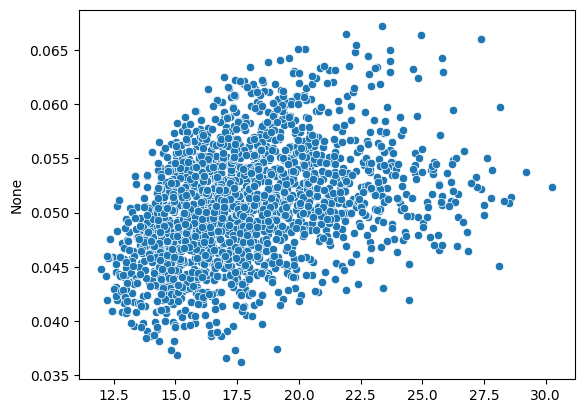

In [461]:
plt.figure()
sns.scatterplot(x = loc_density,  y = g.detach())

In [459]:
import numpy as np
plot_curvature_vs_arclength(rnn=rnn, step_size=0.01, total_time=1.0)

RuntimeError: The size of tensor a (2) must match the size of tensor b (4) at non-singleton dimension 2

In [106]:
plot_avg_crossing_time_vs_g(rnn=rnn, step_size=0.001, total_time=1.0)

NameError: name 'plot_avg_crossing_time_vs_g' is not defined

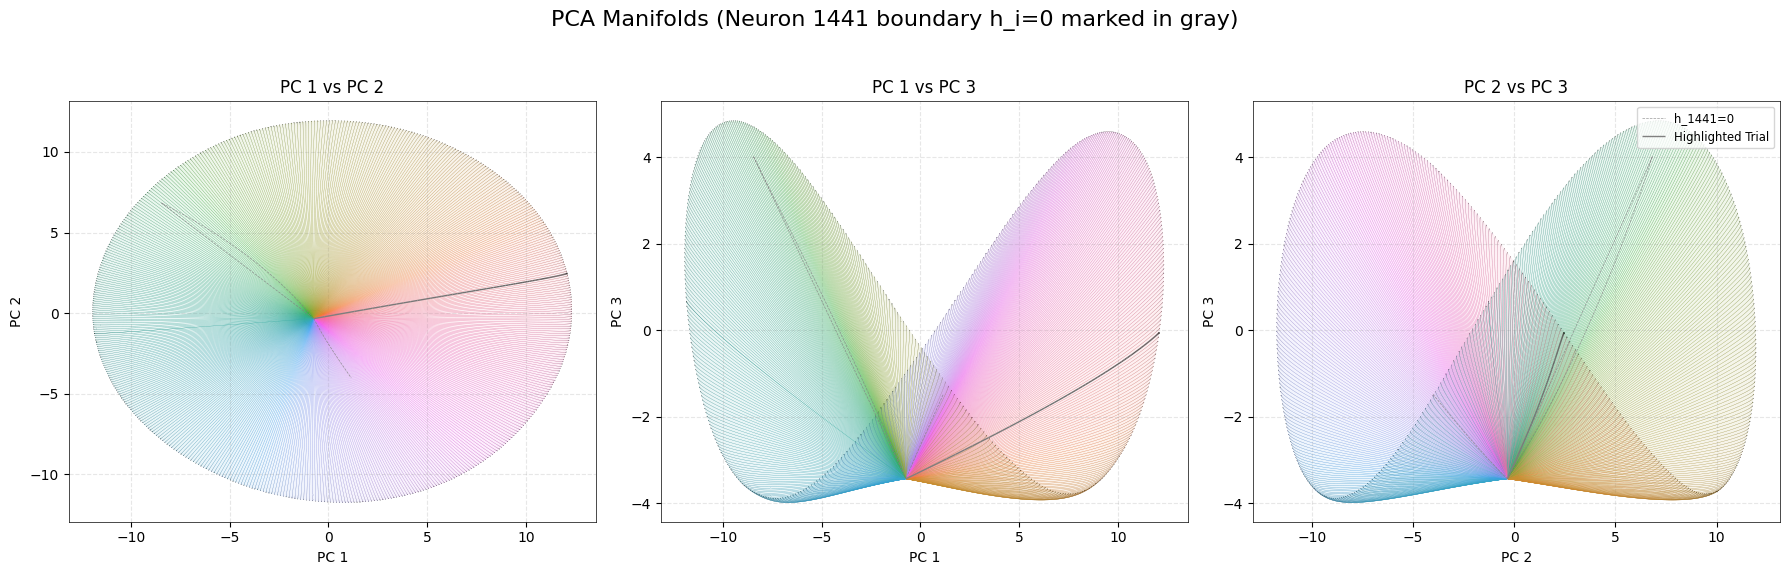

In [64]:
# PCA plot
plot_pca_trajectories(rnn=rnn, step_size=0.05, total_time=10.0)

<Axes: xlabel='None', ylabel='Count'>

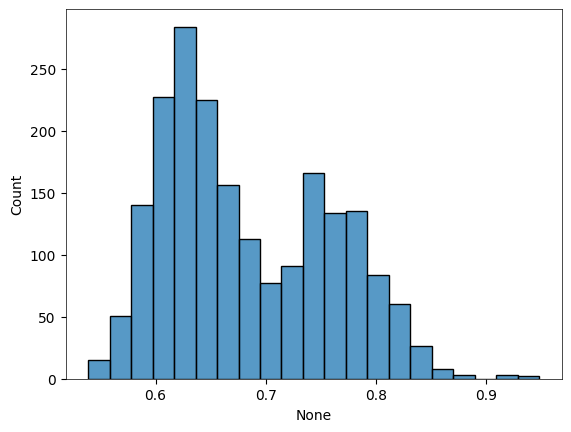

In [39]:
plt.figure()
x = rnn(u).detach()
std = torch.std(x,dim=(0,1))
sns.histplot(x = g.detach())

In [67]:
torch.std(g)

tensor(0.0033, grad_fn=<StdBackward0>)

In [988]:
##########################################
########## Plotting manifolds ############
##########################################
u, z, mask, conditions = generate_trials(n_trials=1,n_conditions =100,n_t =100)

rnn.sigma_in =0
x = rnn(u,training=False)
z_scored_y, g, _ = compute_zscored_derivatives(x, rnn, u, dt=rnn.alpha, total_time=100*rnn.alpha, epsilon=1e-8)
g = g.detach().numpy()

#x = (x - torch.mean(x,dim=(0,1)))/ torch.std(x,dim=(0,1))
x = x.detach().numpy()
pca = PCA().fit(x.reshape(-1,x.shape[2]))


rows = []
x = torch.tensor(x).float()
#net.recurrent_layer.weight.data = net.recurrent_layer.weight.data + .005*(2*torch.randn_like(net.recurrent_layer.weight.data)-1)
h = rnn.recurrent_layer(x)+rnn.input_layer(u)

flow_field = -x + rnn.activation(h)
# Use numerically stable second derivative of Softplus: f''(h) = beta * sigmoid(beta*h) * (1-sigmoid(beta*h))
sigmoid = torch.sigmoid(rnn.beta * h)
b = rnn.beta * sigmoid * (1 - sigmoid)
curvature =  (flow_field @ rnn.recurrent_layer.weight.data.t(
))**2 * b

x.shape

torch.Size([1000, 100, 100])

In [989]:
import numpy as np
import pandas as pd
neuron = np.argsort(np.mean(g,axis = (0,1)))[0]
for trial in range(x.shape[0]):
    trajectory = x[trial,:,:]
    proj_trajectory = pca.transform(trajectory)
    for t in range(x.shape[1]-1):

        rows.append({'t': t,
             'trial': trial,
             'x': proj_trajectory[t,0],
             'y': proj_trajectory[t,1],
             'z': proj_trajectory[t,2],
             'c': torch.linalg.norm(curvature[trial,t,:]).item(),
            'g': g[trial,t,neuron].item(),

              'b':torch.linalg.norm(b[trial,t,neuron]).item()})

new_df = pd.DataFrame(rows)


In [990]:
curvature.shape

torch.Size([1000, 100, 100])

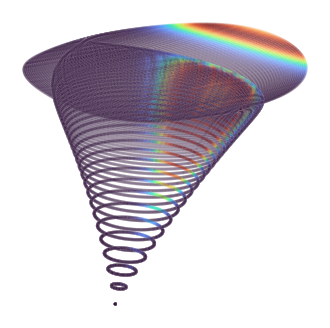

In [991]:
fig = plt.figure(figsize=(4,4))
from scipy.spatial import ConvexHull
gs = gridspec.GridSpec(1,1)

ax0=fig.add_subplot(gs[0,0])

sns.scatterplot(data = new_df, x = 'z', y = 'y', hue = 'b',palette = 'turbo',s=6,legend=False,alpha = .1,ax=ax0)

for ax in [ax0]:
    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)
    ax.spines['bottom'].set_visible(False)
    ax.spines['left'].set_visible(False)
    ax.axes.get_xaxis().set_visible(False)
    ax.axes.get_yaxis().set_visible(False)
    # plt.savefig('Figures/Figure_boundary_8.jpg',
    #         format='jpeg',
    #         dpi=450,
    #         bbox_inches='tight', transparent=True)
# ax.spines['left'].set_color('black')
# ax.spines['bottom'].set_color('black')


In [992]:
import numpy as np

import plotly.graph_objects as go
from plotly.subplots import make_subplots
import plotly.express as px


fig = make_subplots(
     rows=1, cols=1,
     specs=[[{"type": "scene"}]])

sub_df = new_df
fig.add_trace(go.Scatter3d(x=sub_df.x.values,
                          y=sub_df.y.values,
                          z=sub_df.z.values,
                              mode='markers',

                        marker=dict(
                            color=sub_df.b.values,
                            opacity=1,
                            size = 2
                        )), row=1, col=1)
#px.colors.diverging.balance
#
fig.update_layout( scene = dict(xaxis = dict(showgrid = False,showticklabels = False),
                                   yaxis = dict(showgrid = False,showticklabels = False),
                                   zaxis = dict(showgrid = False,showticklabels = False),

             ))
fig.update_scenes(xaxis_visible=False, yaxis_visible=False,zaxis_visible=False )

Text(0, 0.5, '$\\dot{y}_i$')

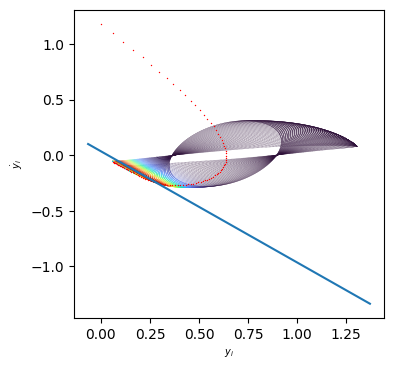

In [1008]:
##########################################
neuron = np.argsort(np.mean(g,axis = (0,1)))[50]
x = rnn(u)
z_scored_y, dot_z = compute_zscored_derivatives(x, dt=rnn.alpha, epsilon=1e-8)
#g = torch.mean(torch.abs(dot_z),dim = (0,1))
#slam = calculate_discrete_intensity(x).detach()
#x = (x - torch.mean(x,dim=(0,1)))/ torch.std(x,dim=(0,1))
x = x.detach()
h = rnn.recurrent_layer(x)+rnn.input_layer(u)
xdot = -x + rnn.activation(h).detach()
kinkiness = calculate_phase_curvature(torch.FloatTensor(x), dt=rnn.alpha)
#neuron = np.argsort(np.mean(np.abs(g),axis=(0,1)))[0]
#curvature = compute_instantaneous_curvature(x[trial,:,neuron], xdot[trial,:,neuron], dt=1)

rows=[]
for trial in range(x.shape[0]):
    for t in range(x.shape[1]-5):
        rows.append({'t':t,
                     'trial':trial,
                     'x':x[trial,t,neuron].item(),
                     'y':xdot[trial,t,neuron].item(),
                     'h':h[trial,t,neuron].item(),
                     'c':curvature[trial,t,neuron].item(),
                     'b':b[trial,t,neuron].item(),
                     'k':kinkiness[trial,t,neuron].item(),
                     'doty':dot_z[trial,t,neuron].item()})
df = pd.DataFrame(rows)
fig = plt.figure(figsize=(4,4))
from scipy.spatial import ConvexHull
gs = gridspec.GridSpec(1,1)

ax=fig.add_subplot(gs[0,0])
sns.scatterplot(data = df[df.t>50], x = 'x',y='y',hue='b',legend=False,ax=ax,lw=0,s=.1,palette = 'turbo')
sns.scatterplot(data = df[df.trial==12], x = 'x',y='y',color='red',legend=False,ax=ax,lw=0,s=1)
xmin, xmax = ax.get_xlim()

a = -1  # Slope
int = np.log(2)/rnn.beta  # Intercept

# Create data
x = np.linspace(xmin, xmax, 100)
y = a * x + int
ax.plot(x, y, label=f'y = {a}x + {b}')

y = -x
#ax.plot(x, y, label=f'y = {a}x + {b}')
ax.set_xlabel(r'$y_i$',fontsize=7)
ax.set_ylabel(r'$\dot{y}_i$',fontsize=7)
#ax.set_ylim(-.1,1)
# ax.set_xlim(0,.1)
# ax.spines['right'].set_visible(False)
# ax.spines['top'].set_visible(False)
# ax.spines['bottom'].set_visible(False)
# ax.spines['left'].set_visible(False)
# ax.axes.get_xaxis().set_visible(False)
# ax.axes.get_yaxis().set_visible(False)
#ax.set_aspect('equal')


In [930]:
rnn.alpha

tensor(0.0500)

In [146]:
import torch

def calculate_phase_curvature(y, dt=1.0, epsilon=1e-6):
    """
    Calculates the geometric curvature (kinkiness) of the projected phase plot
    (dot_y_i vs y_i) for a CTRNN trajectory tensor.

    Parameters:
    -----------
    y : torch.Tensor
        Shape (trials, time, neurons). The state trajectories of the neurons.
    dt : float
        The time step between successive samples along the time dimension.
    epsilon : float
        A small regularization constant to prevent division by zero in flat regions.

    Returns:
    --------
    curvature : torch.Tensor
        Shape (trials, time - 4, neurons). The geometric curvature values.
        Note: The time dimension shrinks by 4 due to boundary effects of central
        finite differences up to the 3rd derivative.
    """
    # Check dimensions
    assert y.dim() == 3, "Input tensor must have shape (trials, time, neurons)"
    assert y.shape[1] >= 5, "Time dimension must be >= 5 to compute 3rd order central differences."

    # 1. Compute 1st time derivative (velocity) via central difference
    # y_dot[t] = (y[t+1] - y[t-1]) / (2*dt)
    # This trims 1 step from both ends: time -> time - 2
    y_1st = (y[:, 2:, :] - y[:, :-2, :]) / (2.0 * dt)

    # To compute higher derivatives cleanly, we slice the baseline y to match the trimmed time
    y_trimmed = y[:, 1:-1, :]

    # 2. Compute 2nd time derivative (acceleration) via central difference on y_1st
    # This trims another step from both ends: (time - 2) -> time - 4
    y_2nd = (y_1st[:, 2:, :] - y_1st[:, :-2, :]) / (2.0 * dt)

    # 3. Compute 3rd time derivative (jerk)
    # To keep dimensions aligned, we compute the 2nd derivative of y_1st directly,
    # which mathematically corresponds to the 3rd derivative of our base y.
    # We apply the same central difference spacing to y_1st to get y_3rd at the matched time window.
    # y_3rd[t] = (y_1st[t+1] - 2*y_1st[t] + y_1st[t-1]) / (dt^2) -> centered derivative
    # Alternately, doing a central difference of the 2nd derivative:
    # Let's align all tensors to the final (time - 4) inner window:

    # Slices to match the (time - 4) final window:
    # y_1st was (time - 2). To match (time - 4), slice off the edges:
    y_1st_aligned = y_1st[:, 1:-1, :]

    # y_3rd calculated using a central difference over the 2nd derivative window
    # requires computing 2nd derivative manually with a wider stencil, or diffing the 2nd derivative.
    # Cleanest way for 3rd derivative at central point:
    # y^(3)[t] = (-y[t-2] + 2y[t-1] - 2y[t+1] + y[t+2]) / (2 * dt^3)
    y_3rd = (-y[:, :-4, :] + 2.0*y[:, 1:-3, :] - 2.0*y[:, 3:-1, :] + y[:, 4:, :]) / (2.0 * (dt**3))

    # 4. Apply the Parametric Curvature Formula
    # Numerator: |x_dot * y_ddot - y_dot * x_ddot|
    # where x = y_i (so x_dot = y_1st, x_ddot = y_2nd)
    # and y = y_dot_i (so y_dot = y_2nd, y_ddot = y_3rd)
    numerator = torch.abs(y_1st_aligned * y_3rd - (y_2nd ** 2))

    # Denominator: (x_dot^2 + y_dot^2)^(3/2) -> (y_1st^2 + y_2nd^2)^(3/2)
    denominator = (y_1st_aligned ** 2 + y_2nd ** 2 + epsilon) ** 1.5

    curvature = numerator / denominator
    return curvature

# ==========================================
# Example Usage:
# ==========================================




In [147]:
    # Run the calculator
kinkiness = calculate_phase_curvature(torch.FloatTensor(x), dt=rnn.alpha)


# Notice the output time is 96 (100 - 4 boundary steps)

# Check max kinkiness location for Neuron 0
max_kink_time_idx = torch.argmax(kinkiness[0, :, 406])
print(f"Highest kink for Neuron 0 found at time index: {max_kink_time_idx.item() + 2}")
    # (+2 adjusts back to original index space)

Highest kink for Neuron 0 found at time index: 2


In [149]:
torch.argmax(torch.mean(kinkiness[:,:,0],dim=1))

tensor(36)

In [ ]:
np.argsort(max_curvature.detach())[-1]

In [ ]:
plt.figure()
sns.histplot(x=max_curvature.detach())

In [ ]:
import torch

def calculate_nonlinearity_map(y_tensor, W, b, beta=1.0):
    """
    Returns a tensor of shape (n_trial, n_time, n_neurons) containing
    the normalized non-linearity index for every neuron at every moment.
    """
    # 1. Compute pre-activation inputs
    # y_tensor shape: (n_trial, n_time, n_neurons)
    u = torch.matmul(y_tensor, W.t()) + b

    # 2. Compute the vector field (the 'flow')
    # f(u) = (1/beta) * log(1 + exp(beta * u))
    f_u = torch.nn.functional.softplus(u, beta=beta)
    F_y = -y_tensor + f_u

    # 3. Compute the change in input 'u' along the flow (direction of F_y)
    # AV represents the 'input velocity' for each neuron
    AV = torch.matmul(F_y, W.t())

    # 4. Derivatives for Softplus with Beta gain
    # f'(u) is the sigmoid (slope)
    # f''(u) is the curvature
    sigma_beta_u = torch.sigmoid(beta * u)
    f_double_prime = beta * sigma_beta_u * (1 - sigma_beta_u)

    # 5. Calculate Taylor Coefficients
    # Linear coefficient (L): the first-order rate of change
    # Note: F_y is the actual change, we check the linear prediction error
    L = torch.abs(-F_y + sigma_beta_u * AV)

    # Quadratic coefficient (E): the second-order curvature contribution
    E = 0.5 * torch.abs(f_double_prime * (AV**2))

    # 6. Compute Normalized Index
    # Shape: (n_trial, n_time, n_neurons)
    index_tensor = E / (L + 1e-12)

    return index_tensor

In [ ]:

x = rnn(u)
x = x.detach()
curvature = calculate_nonlinearity_map(x, rnn.recurrent_layer.weight.data, rnn.input_layer(u)[0,0,:], beta=rnn.beta)

In [ ]:
plt.figure()
for i in range(curvature.shape[0]):
    plt.plot(curvature[i,:,79].detach())

In [ ]:
torch.argsort(torch.mean(curvature,dim=(0,1)))[0]

In [ ]:
torch.mean(curvature,dim=(0,1))[81]

Shape of R_all (Rates):   (4000, 800)
Shape of H_all (Inputs):  (4000, 800)
Shape of Metric_all:      (4000, 800)


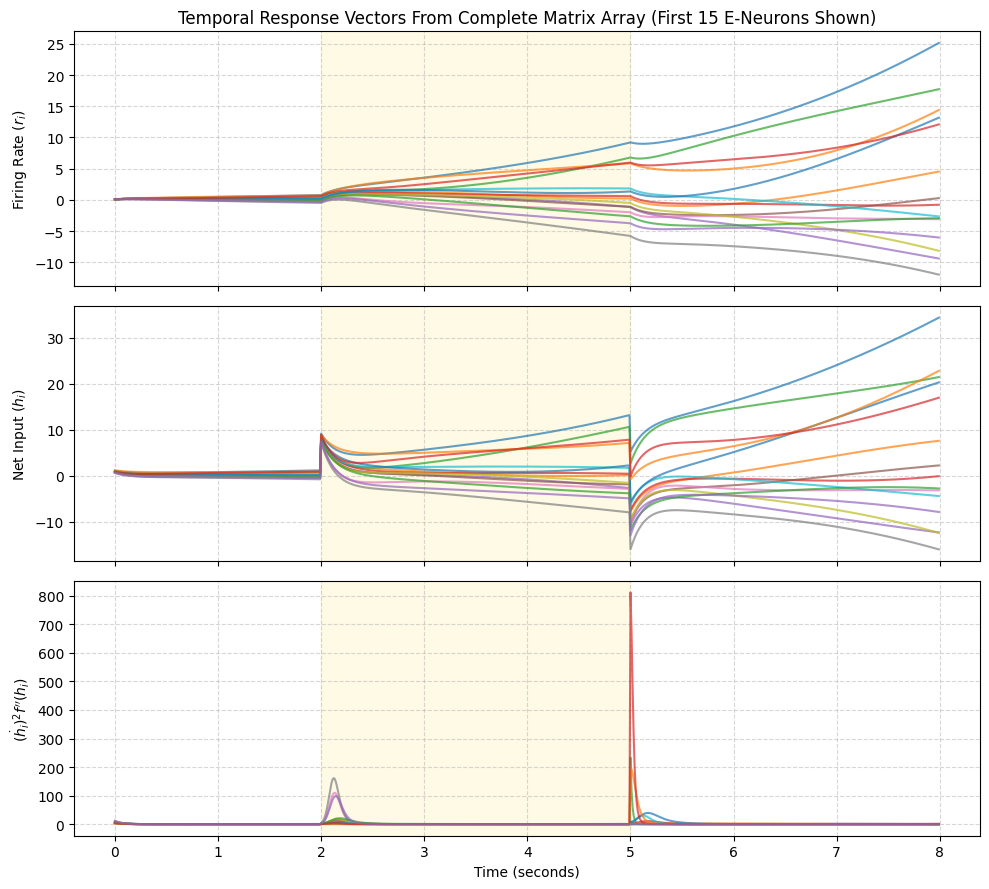

In [449]:
import numpy as np
import matplotlib.pyplot as plt

def softplus(x):
    """f(h) = ln(1 + e^x)"""
    return np.log(1.0 + np.exp(np.clip(x, -20, 20)))

def softplus_pprime(x):
    """Second derivative f''(h) = e^x / (1 + e^x)^2"""
    ex = np.exp(np.clip(x, -20, 20))
    return ex / ((1.0 + ex) ** 2)

# --- 1. Simulation & Population Configuration ---
N = 4000                      # Total size of the large network
p_e = 0.8                     # 80% Excitatory, 20% Inhibitory split
N_e = int(N * p_e)            # 1600 E neurons
N_i = N - N_e                 # 400 I neurons

dt = 0.01                     # Integration time step (seconds)
t = np.arange(0, 8.0, dt)     # Simulate for 8 seconds
N_steps = len(t)

# --- 2. Scaling & Structural Balance ---
scale = 1.0 / np.sqrt(N)
w_e = 1.0 * scale
w_i = -4.5 * scale

# Construct the random recurrent block matrix (Enforces Dale's Law)
W = np.zeros((N, N))
W[:, :N_e] = np.random.uniform(0, 2 * w_e, size=(N, N_e))
W[:, N_e:] = np.random.uniform(2 * w_i, 0, size=(N, N_i))

# --- 3. Initial States & Full Array Allocation ---
r = np.ones(N)*.1          # Initialize all firing rates at 10%
I_bias = 1.5                  # Tonic baseline current

# Allocate arrays of shape (N, N_steps) to record every neuron over time
R_all = np.zeros((N, N_steps))
H_all = np.zeros((N, N_steps))
Metric_all = np.zeros((N, N_steps))

# --- 4. Forward Euler Simulation Loop ---
for k in range(N_steps):
    # Apply a sharp square pulse transient from t = 2.0s to t = 5.0s
    if 2.0 <= t[k] < 5.0:
        I_ext = 8.0
    else:
        I_ext = 0

    # 1. Compute h_i for all neurons
    h = np.dot(W, r) + I_bias + I_ext

    # 2. Compute dot_r_j = -r_j + f(h_j)
    dot_r = -r + h#softplus(h)

    # 3. Compute dot_h_i = Sum(W_ij * dot_r_j)
    dot_h = np.dot(W, dot_r)

    # 4. Compute f''(h_i)
    f_pprime = softplus_pprime(h)

    # 5. Compute the requested metric: (dot_h_i)^2 * f''(h_i)
    metric = (dot_h ** 2) * f_pprime

    # Save the full state into arrays at time index k
    R_all[:, k] = r
    H_all[:, k] = h
    Metric_all[:, k] = metric

    # Dynamics update
    r = r + dt * dot_r

# --- Verification of Shapes ---
print(f"Shape of R_all (Rates):   {R_all.shape}")
print(f"Shape of H_all (Inputs):  {H_all.shape}")
print(f"Shape of Metric_all:      {Metric_all.shape}")

# --- 5. Corrected Visualization of Matrix Subsets ---
# We pass 't' first, and Matplotlib will correctly plot each row of the transposed matrix as a separate line.
fig, axes = plt.subplots(3, 1, figsize=(10, 9), sharex=True)

# Top Plot: Firing Rates for neurons 0 to 15
axes[0].plot(t, R_all[:15, :].T, alpha=0.7, lw=1.5)
axes[0].axvspan(2.0, 5.0, color='gold', alpha=0.1, label='External Stimulus')
axes[0].set_ylabel('Firing Rate ($r_i$)')
axes[0].set_title(f'Temporal Response Vectors From Complete Matrix Array (First 15 E-Neurons Shown)')
axes[0].grid(True, linestyle='--', alpha=0.5)

# Middle Plot: Net inputs h_i for neurons 0 to 15
axes[1].plot(t, H_all[:15, :].T, alpha=0.7, lw=1.5)
axes[1].axvspan(2.0, 5.0, color='gold', alpha=0.1)
axes[1].set_ylabel('Net Input ($h_i$)')
axes[1].grid(True, linestyle='--', alpha=0.5)

# Bottom Plot: Metric values for neurons 0 to 15
axes[2].plot(t, Metric_all[:15, :].T, alpha=0.7, lw=1.5)
axes[2].axvspan(2.0, 5.0, color='gold', alpha=0.1)
axes[2].set_xlabel('Time (seconds)')
axes[2].set_ylabel(r'$(\dot{h}_i)^2 f^{\prime\prime}(h_i)$')
axes[2].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

Text(-0.05, 1, 'c')

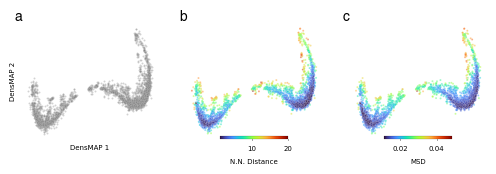

In [450]:
from sklearn.model_selection import KFold
from tqdm.auto import tqdm
import os
import sys
import matplotlib.gridspec as gridspec
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

y = R_all[:,200:500]

#g = np.mean(y, axis=1)
#y = y+.1*(2*np.random.randn(y.shape[0], y.shape[1])-1)
z = (y-np.mean(y,axis = 1,keepdims=True))/np.std(y,axis = 1,keepdims=True)

g = np.mean(np.abs(np.diff(z, axis = 1)),axis = 1)

y = y+.05*(2*np.random.randn(y.shape[0], y.shape[1])-1)
y = (y-np.mean(y,axis = 1,keepdims=True))/np.std(y,axis = 1,keepdims=True)


z_neurons = umap.UMAP(densmap=True,dens_lambda=1,n_neighbors=1000).fit_transform(y)
loc_density = get_density(y, k=50).numpy()




fig = plt.figure(figsize=(6, 1.5))
gs = gridspec.GridSpec(1, 3)
ax1 = plt.subplot(gs[0])
ax2 = plt.subplot(gs[1])
ax3 = plt.subplot(gs[2])








# Gray
sns.scatterplot(x=z_neurons[:, 0], y=z_neurons[:, 1], color='gray', s=2, alpha=.35,ax=ax1)

# NN Distance
sns.scatterplot(x=z_neurons[:, 0], y=z_neurons[:, 1], c=loc_density,cmap  = 'turbo', s=2, alpha=.5,ax=ax2)
cax = inset_axes(
        ax2, width="50%", height="2%",
        loc="lower center", borderpad=0
    )

norm = plt.Normalize(loc_density.min(), loc_density.max())
sm = plt.cm.ScalarMappable(cmap="turbo", norm=norm)
cb = fig.colorbar(sm, cax=cax, orientation="horizontal")
cb.outline.set_linewidth(0.1)
cax.set_xlabel("N.N. Distance", fontsize=5, labelpad=5)
cax.xaxis.set_tick_params(size=1, width=.5, color="black")
cax.xaxis.set_tick_params(labelsize=5)

# MSD

sns.scatterplot(x=z_neurons[:, 0], y=z_neurons[:, 1], c=g,cmap='turbo', s=2, alpha=.5,ax=ax3)
cax = inset_axes(
        ax3, width="50%", height="2%",
        loc="lower center", borderpad=0
    )
norm = plt.Normalize(g.min(), g.max())
sm = plt.cm.ScalarMappable(cmap="turbo", norm=norm)
cb = fig.colorbar(sm, cax=cax, orientation="horizontal")
cb.outline.set_linewidth(0.1)
cax.set_xlabel("MSD", fontsize=5, labelpad=5)
cax.xaxis.set_tick_params(size=1, width=.5, color="black")
cax.xaxis.set_tick_params(labelsize=5)





# 4. Global figure customizations
#fig.suptitle("Main Title for All 5 Subplots", fontsize=18, fontweight="bold", y=1.05)

# Automatically adjusts subplot parameters so that the labels don't overlap
for ax in [ax1,ax2,ax3]:
    for spine in ax.spines.values():
        spine.set_visible(False)

    # 2. Hide the tick marks and tick numbers
    ax.set_xticks([])
    ax.set_yticks([])

    # 3. Add your labels normally
    ax.set_xlabel('')
    ax.set_ylabel('')



ax1.set_xlabel('DensMAP 1',fontsize = 5)
ax1.set_ylabel('DensMAP 2',fontsize = 5)



#fig.subplots_adjust(wspace=0.2)

# Figure labels
ax1.text(-0.05, 1., 'a', transform=ax1.transAxes,
         fontsize=10, fontweight='bold', va='bottom', ha='left',fontname = 'Helvetica')
ax2.text(-0.05, 1, 'b', transform=ax2.transAxes,
         fontsize=10, fontweight='bold', va='bottom', ha='left',fontname = 'Helvetica')
ax3.text(-0.05, 1, 'c', transform=ax3.transAxes,
         fontsize=10, fontweight='bold', va='bottom', ha='left',fontname = 'Helvetica')







In [439]:
R_all.shape

(4000, 800)

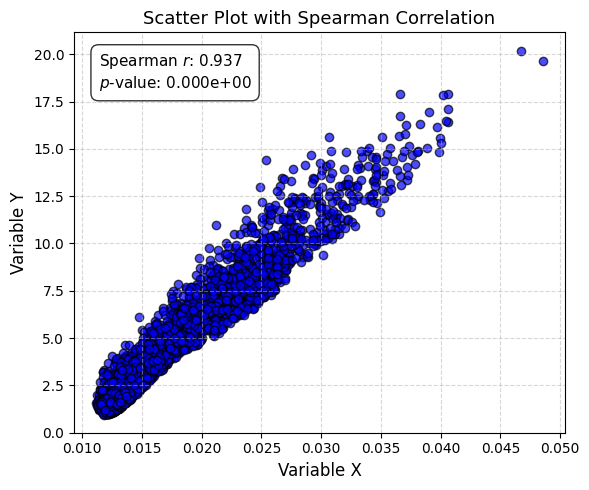

In [451]:
import scipy

spearman_r, p_value = scipy.stats.spearmanr(g, loc_density)

# 3. Create the scatter plot
plt.figure(figsize=(6, 5))
plt.scatter(g, loc_density, color='blue', alpha=0.7, edgecolors='k', label='Data points')

# 4. Display the Spearman r on the plot
# Placing the text dynamically in the upper left corner of the axes
text_str = f"Spearman $r$: {spearman_r:.3f}\n$p$-value: {p_value:.3e}"
plt.gca().text(0.05, 0.95, text_str, transform=plt.gca().transAxes,
            fontsize=11, verticalalignment='top',
            bbox=dict(boxstyle='round,pad=0.5', facecolor='white', alpha=0.8))

# 5. Add labels and layout adjustments
plt.xlabel('Variable X', fontsize=12)
plt.ylabel('Variable Y', fontsize=12)
plt.title('Scatter Plot with Spearman Correlation', fontsize=13)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()